In [1]:
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import re
import string
import requests
import numpy as np
from IPython import display
import matplotlib.pyplot as plt
#import matplotlib as mpl

from common.optim.utils import MetaData
from common.optim.optimiser_netline_v3 import NetLine
from common.optim.optimiser_dz_v3 import NetDz
from common.optim.optimizer_pack1 import AdamS
#from common.experiments_util import initialise_netline

#### Metaparams

In [2]:
# parameters for dataset
CONTEXT_LENGTH = 9 # context length
TEXT_STRIDE = 3 # skipping
# parameters for dataloder
BATCH_SIZE = 32
# parameters for net
EMBEDDING_DIM = 196
# parameters for traning
NUM_EPOCHS=25

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


#### TEXT TO LOAD

In [3]:
# get raw text from internet
#url = 'https://www.gutenberg.org/files/2600/2600-0.txt'
url = 'https://www.gutenberg.org/files/35/35-0.txt'
book = requests.get(url)

# extract just the text and have a look at it
text = book.text
#print(type(text))
print(f"Text has {len(text)} symbols" )


Text has 179799 symbols


In [4]:
# character strings to replace with space
strings2replace = [ '\r\n\r\nâ\x80\x9c','â\x80\x9c','â\x80\x9d','\r\n','â\x80\x94','â\x80\x99','â\x80\x98','_', ]

# use regular expression (re) to replace those strings with space
for str2match in strings2replace:
  text = re.compile(r'%s'%str2match).sub(' ',text)

# remove non-ASCII characters and numbers, and make lower-case
text = re.sub(r'[^\x00-\x7F]+', ' ', text)
text = re.sub(r'\d+','',text).lower()

# split into words with >1 letter
words = re.split(fr'[{string.punctuation}\s]+',text)
words = [item.strip() for item in words if item.strip()]
words = [item for item in words if len(item)>1]

# create the vocabulary (lexicon)
vocab  = sorted(set(words))
nWords = len(words)
nVocab = len(vocab)

# encoder/decoder look-up-tables (as python dictionaries)
word2idx = {w:i for i,w in enumerate(vocab)}
idx2word = {i:w for i,w in enumerate(vocab)}

# show a few keys in the dictionary
print(f'The book contains {nWords:,} words, {nVocab:,} of which are unique and comprise the vocab.')
#print(f'\n\nFirst 10 vocab words:\n',list(word2idx.keys())[:10])

The book contains 30,699 words, 4,589 of which are unique and comprise the vocab.


#### DATA SET

In [5]:
class WordDataset(Dataset):
  def __init__(self, text, word2idx, context_length=8, stride=4):

    # initialize
    self.inputs  = []
    self.targets = []
    self.word2idx = word2idx  # stored locally in the object

    # overlapping sequences of context_length
    for i in range(0,len(text)-context_length-1,stride):

      # get a few words
      in_seq   = text[i : i+context_length]
      targ_seq = text[i+context_length+1] #text[i+1 : i+context_length+1]

      # append to the lists
      self.inputs.append(torch.tensor([word2idx[w] for w in in_seq]))
      self.targets.append(torch.tensor(word2idx[targ_seq]))

  def __len__(self):
    return len(self.inputs)

  def __getitem__(self, idx):
    return self.inputs[idx], self.targets[idx]


# create an instance!
text_dataset = WordDataset(words,word2idx,CONTEXT_LENGTH,TEXT_STRIDE)

text_dataset[4]

(tensor([4451,  783, 2167, 2005, 4042, 2416, 2006, 4042, 4109]), tensor(3309))

#### DATA LOADER

In [6]:
dataloader = DataLoader(
                text_dataset,
                batch_size = BATCH_SIZE, # 2 for looking; BATCH_SIZE for training
                shuffle    = True,
                drop_last  = True
            )

# let's have a look at the indices
X,y = next(iter(dataloader))
print('Inputs:')
print(X), print('')

print('Targets:')
print(y), print('\n\n\n')

# and the words
print('Inputs in words (first batch):')
print([idx2word[item.item()] for item in X[0]])
print('')

print('Targets in words (first batch):')
print(idx2word[y[0].item()])

Inputs:
tensor([[ 815,  137, 2041,   96, 4042, 1025, 2731, 4037,  137],
        [3933, 4408, 3831, 2041, 2848,    7, 4042, 1951, 4408],
        [3527,  989, 2470, 4119, 2321, 1901, 1122,  137, 3152],
        [1122, 2740, 4042, 1216, 1572, 4042, 4091, 2731, 4042],
        [4031, 1141, 2731, 2414, 1897, 2041, 4041, 3257,  137],
        [1545, 2609, 2163, 1660,  255, 1492, 3414, 4077, 2731],
        [4042, 3578, 3125, 2731, 4042, 2572, 3715, 2100,  137],
        [1815, 1742, 2783,  137, 4042,  386, 2731,  927,  519],
        [3431, 1865,  373, 4073, 4408,  151,  213, 2731, 4042],
        [4042,  621, 3465, 4119, 2608, 1385, 4119,  319,  501],
        [4042, 1264, 1142, 2468, 3951, 4581, 2186, 4408, 4042],
        [  69, 2731, 4042,  902, 3055,  230, 1861, 3388, 4119],
        [4119, 3874,   75, 4408, 4352, 4117, 4133,   71, 4042],
        [2347, 3681, 2041, 2553, 4408, 4457, 4119, 4042, 3625],
        [ 137, 1815, 4119, 3874, 2732, 4119, 4042, 2309,  501],
        [4042, 3723, 2731, 1144,

#### Model to learn embeddings

In [7]:
class EmbeddingModel(nn.Module):
  def __init__(self, vocab_size, embedding_dim, context_size):
    super(EmbeddingModel, self).__init__()

    # embedding layer
    self.embeddings = nn.Embedding(vocab_size, embedding_dim)

    # linear layers
    self.linear1 = nn.Linear(context_size * embedding_dim, 256)
    self.linear2 = nn.Linear(256, vocab_size)
    self._init_weights()

  def _init_weights(self):
    # apply Xavier weight distribution
    for param in self.parameters():
      if param.dim()>1: # also excludes biases
        nn.init.xavier_normal_(param)    

  def forward(self, inputs):
    # extract and flatten embeddings [batch_size, context_size * embedding_dim]
    embeds = self.embeddings(inputs).view(inputs.shape[0],-1)

    # fully connected layers
    out = F.relu(self.linear1(embeds))
    return self.linear2(out)


class EmbeddingLogSoftmaxModel(EmbeddingModel):
  def __init__(self, vocab_size, embedding_dim, context_size):
    super().__init__(vocab_size, embedding_dim, context_size)

  def forward(self, inputs):
    out = super().forward(inputs)
    # log softmax for classification (note: NLLLoss expects logprobs as inputs)
    return F.log_softmax(out, dim=1)


# create a model instance!
model = EmbeddingModel(vocab_size=nVocab, embedding_dim=EMBEDDING_DIM, context_size=CONTEXT_LENGTH)
print(model)


EmbeddingModel(
  (embeddings): Embedding(4589, 196)
  (linear1): Linear(in_features=1764, out_features=256, bias=True)
  (linear2): Linear(in_features=256, out_features=4589, bias=True)
)


#### UTILS

In [8]:
ADAMW, NL = 0, 1

def plot_data(total_loss, epoch_effective):
    _, axes = plt.subplots(1, 1, figsize=(10,3))
    axes.plot(total_loss[ADAMW, 0:epoch_effective], color='g',alpha=.5, label='AdamW')
    axes.plot(total_loss[NL, 0:epoch_effective], color='orange',alpha=.5, label='NetLine')
    axes.grid() 
    axes.legend()
    axes.set_xlabel("Epoch (series of gradient descent steps)")
    axes.set_ylabel("Loss value")
    plt.show()


#### Learning cycle

In [9]:
adamw_model = EmbeddingLogSoftmaxModel(vocab_size=nVocab, embedding_dim=EMBEDDING_DIM, context_size=CONTEXT_LENGTH).to(device)
adamw_opt = optim.AdamW(adamw_model.parameters(), lr=.001, weight_decay=.01)
adamw_loss = nn.NLLLoss().to(device)

nl_model = EmbeddingModel(vocab_size=nVocab, embedding_dim=EMBEDDING_DIM, context_size=CONTEXT_LENGTH).to(device)
#nl_opt, nl_sch = initialise_netline(nl_model, MetaData(output_dim=nVocab, device=device), NUM_EPOCHS, lr1=5e-5, lr_max=0.005,\
#                                     momentum=0.9, weight_decay=5e-3, linearity_coeff=0.1, la_alpha=1.0, la_steps=5)
nl_opt = NetLine(model=nl_model, meta=MetaData(output_dim=nVocab, device=device), lr1=5e-5, momentum=.9, weight_decay=.0,\
                 foreach=True, linearity_coeff = 0.1)
nl_opt.lr_averaging_queue_size = 50
nl_loss = nn.CrossEntropyLoss().to(device)


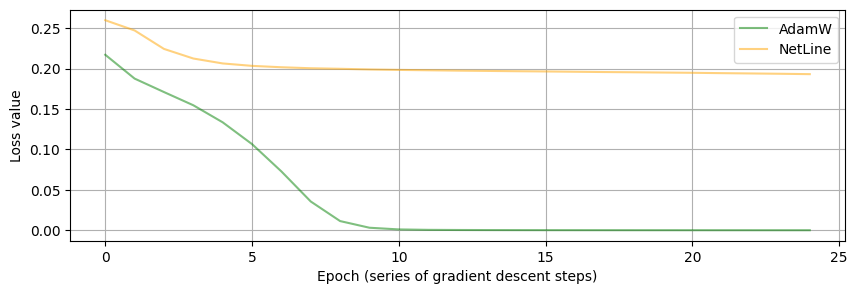

  Finished epoch 25 with loss for adamw = 0.0000 and netline = 0.1931


In [10]:

# initialize losses
total_loss = np.zeros((2, NUM_EPOCHS))

for epoch in range(NUM_EPOCHS):

    # initialize
    aw_epoch_loss, nl_epoch_loss = .0, .0

    # loop over batches in the data loader
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)

        #AdamW
        adamw_model.zero_grad()
        log_probs = adamw_model(X)
        awloss = adamw_loss(log_probs, y)
        awloss.backward()
        adamw_opt.step()
        # sum the per-epoch losses
        aw_epoch_loss += awloss.item()

        #NetLine
        nl_opt.zero_grad()
        nl_opt.batch_prestep()
        nllogits = nl_model(X)
        nlloss = nl_loss(nllogits, y)
        nlloss.backward()
        #nl_sch.batch_step(X, y, nllogits)
        nl_opt.batch_step(X, y, nllogits, eta_target = .005)
        nl_epoch_loss += nlloss.item()

    #nl_sch.step()

    # scale by the number of tokens in this dataloader
    aw_total = aw_epoch_loss / len(dataloader.dataset)
    nl_total = nl_epoch_loss / len(dataloader.dataset)
    total_loss[ADAMW, epoch] = aw_total
    total_loss[NL, epoch] = nl_total

    # plot the losses
    epoch_effective = epoch+1
    display.clear_output()
    plot_data(total_loss, epoch_effective)
    print(f'  Finished epoch {epoch_effective} with loss for adamw = {aw_total:.4f} and netline = {nl_total:.4f}')


In [11]:
total_loss

array([[2.17089199e-01, 1.87599965e-01, 1.70961414e-01, 1.54604224e-01,
        1.33517421e-01, 1.06538730e-01, 7.27515290e-02, 3.55638624e-02,
        1.13431198e-02, 3.09546855e-03, 1.02509774e-03, 4.89963188e-04,
        3.12249328e-04, 2.22676341e-04, 1.63313433e-04, 1.29360642e-04,
        1.04547699e-04, 8.52585041e-05, 7.02896488e-05, 5.79881766e-05,
        4.81852866e-05, 4.00263960e-05, 3.33187615e-05, 2.78619871e-05,
        2.32516943e-05],
       [2.59814060e-01, 2.47146726e-01, 2.24319742e-01, 2.12438025e-01,
        2.06350146e-01, 2.03349533e-01, 2.01633989e-01, 2.00404133e-01,
        1.99727920e-01, 1.98917964e-01, 1.98349172e-01, 1.97898429e-01,
        1.97444109e-01, 1.97101340e-01, 1.96730349e-01, 1.96430618e-01,
        1.96061910e-01, 1.95704261e-01, 1.95431850e-01, 1.95102776e-01,
        1.94775351e-01, 1.94337405e-01, 1.93960444e-01, 1.93569685e-01,
        1.93099992e-01]])